# Step 1: Data Preparation and SQL Retrieval 

**FMCG Demand Planning and Forecasting: Capstone Project**

What we hope to achieve:

1. Load the data and take a first look
2. Store it in a SQL database and run some queries
3. Check the data quality (missing values, duplicates, labels)
4. Merge the sales data with a promotional calendar.
5. Save the cleaned data for the next step.

### 1. Load the data

In [1]:
# Importing libraries
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Read the CSV file into a df
fmcg_df = pd.read_csv("data/fmcg_sales_3years_1M_rows.csv")
print(fmcg_df.shape)

(1100000, 33)


In [3]:
#Print the first 5 rows
fmcg_df.head()

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.1,1,167.84,151.06,248,0,11,S008,7.53,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.0,0,125.88,125.88,238,0,6,S057,5.19,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.3,1,398.62,279.03,238,0,6,S017,5.59,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.0,0,83.92,83.92,216,0,7,S012,7.81,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.2,1,178.33,142.66,372,0,8,S038,7.62,0.073


In [4]:
#Check the columns and data types
fmcg_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1100000 entries, 0 to 1099999
Data columns (total 33 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   date            1100000 non-null  str    
 1   year            1100000 non-null  int64  
 2   month           1100000 non-null  int64  
 3   day             1100000 non-null  int64  
 4   weekofyear      1100000 non-null  int64  
 5   weekday         1100000 non-null  int64  
 6   is_weekend      1100000 non-null  int64  
 7   is_holiday      1100000 non-null  int64  
 8   temperature     1100000 non-null  float64
 9   rain_mm         1100000 non-null  float64
 10  store_id        1100000 non-null  str    
 11  country         1100000 non-null  str    
 12  city            1100000 non-null  str    
 13  channel         1100000 non-null  str    
 14  latitude        1100000 non-null  float64
 15  longitude       1100000 non-null  float64
 16  sku_id          1100000 non-null  str    
 17  

In [5]:
# The date column was read as text, so I convert it to a proper date format
fmcg_df["date"] = pd.to_datetime(fmcg_df["date"])

#Check the time period covered
print("First date:", fmcg_df["date"].min())
print("Last date:", fmcg_df["date"].max())

First date: 2021-01-01 00:00:00
Last date: 2023-12-31 00:00:00


In [6]:
# How many different stores, SKUs, cities, countries and channels?
print("Stores   :", fmcg_df["store_id"].nunique())
print("SKUs     :", fmcg_df["sku_id"].nunique())
print("Cities   :", fmcg_df["city"].nunique())
print("Countries:", fmcg_df["country"].nunique())
print("Channels :", fmcg_df["channel"].nunique())

Stores   : 13
SKUs     : 102
Cities   : 9
Countries: 7
Channels : 4


### 2. SQL retrieval

The 1.1M rows are big, so I saved them in a SQLite database and use SQL to pull out only what I need.

In [7]:
# Create the data folder if it doesn't exist
os.makedirs("data", exist_ok=True)

# Create a database file and save the DataFrame as a table called "sales"
conn = sqlite3.connect("data/fmcg.db")
fmcg_df.to_sql("sales", conn, if_exists="replace", index=False)

1100000

In [8]:
# Query 1: how many rows and what dates are in the table?
query = """
SELECT COUNT(*) AS total_rows,
       MIN(date) AS first_date,
       MAX(date) AS last_date
FROM sales
"""
pd.read_sql(query, conn)

,total_rows,first_date,last_date
0,1100000,2021-01-01 00:00:00,2023-12-31 00:00:00


In [9]:
# Query 2: WHERE filter - only select the columns I need, for 2023 only
query = """
SELECT date, sku_id, units_sold, list_price, channel
FROM sales
WHERE date >= '2023-01-01'
"""
sales_2023 = pd.read_sql(query, conn)
print(sales_2023.shape)
sales_2023.head()

(366460, 5)


,date,sku_id,units_sold,list_price,channel
0,2023-01-01 00:00:00,SKU0086,14,10.49,Hypermarket
1,2023-01-02 00:00:00,SKU0086,11,10.49,Hypermarket
2,2023-01-03 00:00:00,SKU0086,9,10.49,Hypermarket
3,2023-01-04 00:00:00,SKU0086,8,10.49,Hypermarket
4,2023-01-05 00:00:00,SKU0086,11,10.49,Hypermarket


In [10]:
# Query 3: GROUP BY - total units and net sales for each country
query = """
SELECT country,
       SUM(units_sold) AS total_units,
       SUM(net_sales) AS total_net_sales
FROM sales
GROUP BY country
ORDER BY total_net_sales DESC
"""
pd.read_sql(query, conn)

,country,total_units,total_net_sales
0,Italy,19361774,1.371931e+08
1,Spain,14668017,1.067048e+08
2,Germany,11738571,8.852556e+07
3,Austria,5742174,4.302003e+07
4,France,6014974,4.260161e+07
5,Poland,5860180,4.238526e+07
6,Netherlands,1730292,1.251615e+07


In [11]:
# Query 4: JOIN - first make a small table with one row per store
stores = fmcg_df[["store_id", "city", "latitude", "longitude"]].drop_duplicates()
stores.to_sql("stores", conn, if_exists="replace", index=False)

# Join the sales table with the stores table and total the sales for each city
query = """
SELECT st.city,
       SUM(sa.net_sales) AS total_net_sales
FROM sales AS sa
JOIN stores AS st ON sa.store_id = st.store_id
GROUP BY st.city
ORDER BY total_net_sales DESC
"""
pd.read_sql(query, conn)

,city,total_net_sales
0,Berlin,88525559.01
1,Rome,72437522.63
2,Barcelona,67739349.27
3,Milan,64755553.49
4,Vienna,43020025.97
5,Paris,42601612.57
6,Warsaw,42385262.52
7,Madrid,38965417.77
8,Amsterdam,12516149.60


### 3. Data cleaning

In [12]:
# Missing values in each column
fmcg_df.isnull().sum()

date              0
year              0
month             0
day               0
weekofyear        0
weekday           0
is_weekend        0
is_holiday        0
temperature       0
rain_mm           0
store_id          0
country           0
city              0
channel           0
latitude          0
longitude         0
sku_id            0
sku_name          0
category          0
subcategory       0
brand             0
units_sold        0
list_price        0
discount_pct      0
promo_flag        0
gross_sales       0
net_sales         0
stock_on_hand     0
stock_out_flag    0
lead_time_days    0
supplier_id       0
purchase_cost     0
margin_pct        0
dtype: int64

In [13]:
# Duplicate rows
# 1) Rows that are completely identical
print("Identical rows:", fmcg_df.duplicated().sum())

# 2) Rows with the same store, SKU and date
print("Same store + SKU + date:", fmcg_df.duplicated(subset=["store_id", "sku_id", "date"]).sum())

# 3) The key suggested in the project guide: SKU + date + channel + city
print("Same SKU + date + channel + city:", fmcg_df.duplicated(subset=["sku_id", "date", "channel", "city"]).sum())

Identical rows: 0
Same store + SKU + date: 0
Same SKU + date + channel + city: 67890


In [14]:
# Why does the guide's key show duplicates? Look at stores that share the same city and channel
store_counts = fmcg_df.groupby(["city", "channel"])["store_id"].nunique()
print(store_counts)

city       channel    
Amsterdam  Convenience    1
Barcelona  E-commerce     1
           Supermarket    1
Berlin     Hypermarket    2
Madrid     E-commerce     1
Milan      E-commerce     1
           Supermarket    1
Paris      Hypermarket    1
Rome       Hypermarket    1
           Supermarket    1
Vienna     Hypermarket    1
Warsaw     Hypermarket    1
Name: store_id, dtype: int64


Berlin has **two hypermarkets** (two different stores), so their rows look like duplicates on the data's key but they are real, separate sales. Each row is unique by store + SKU + date.

In [15]:
# Check the category labels for spelling or spacing problems
for col in ["country", "city", "channel", "category"]:
    print(fmcg_df[col].value_counts())
    print()

country
Italy          350400
Spain          262800
Germany        175200
Poland          87600
France          87600
Austria         87600
Netherlands     48800
Name: count, dtype: int64

city
Berlin       175200
Rome         175200
Milan        175200
Barcelona    175200
Warsaw        87600
Paris         87600
Vienna        87600
Madrid        87600
Amsterdam     48800
Name: count, dtype: int64

channel
Hypermarket    525600
Supermarket    262800
E-commerce     262800
Convenience     48800
Name: count, dtype: int64

category
Beverages        266085
Snacks           261705
Personal Care    199290
Dairy            196005
Home Care        176915
Name: count, dtype: int64



In [16]:
# Check that gross sales = units sold x list price
# (the biggest difference should be tiny, just rounding)
difference = (fmcg_df["gross_sales"] - fmcg_df["units_sold"] * fmcg_df["list_price"]).abs()
print("Biggest difference:", difference.max())

Biggest difference: 9.094947017729282e-13


In [17]:
# Zero-sales days and stockout days
print("Days with zero units sold:", (fmcg_df["units_sold"] == 0).sum())
print("Stockout days:", fmcg_df["stock_out_flag"].sum())
print("Stockout rate:", round(fmcg_df["stock_out_flag"].mean() * 100, 1), "%")

Days with zero units sold: 3092
Stockout days: 33114
Stockout rate: 3.0 %


### 4. Merge with the promo calendar
A left join keeps every sales row. Days without a promotion get no match, so they are = 0.

In [18]:
# Build the promo calendar: only the days when a promotion ran
promo_calendar = fmcg_df.loc[fmcg_df["promo_flag"] == 1, ["store_id", "sku_id", "date", "discount_pct"]]
promo_calendar = promo_calendar.rename(columns={"discount_pct": "promo_discount"})
promo_calendar["on_promo"] = 1
print("Number of promo days:", len(promo_calendar))

Number of promo days: 88257


In [19]:
# Remove the old promo columns, then left join the calendar back on
sales = fmcg_df.drop(columns=["promo_flag", "discount_pct"])
sales = sales.merge(promo_calendar, on=["store_id", "sku_id", "date"], how="left")

# Days with no match are NaN, so fill them with 0
sales["on_promo"] = sales["on_promo"].fillna(0)
sales["promo_discount"] = sales["promo_discount"].fillna(0)

In [20]:
# Check the merge worked: same number of rows, and same number of promo days as before
print("Rows before:", len(fmcg_df), "| Rows after:", len(sales))
print("Promo days before:", fmcg_df["promo_flag"].sum(), "| Promo days after:", int(sales["on_promo"].sum()))

Rows before: 1100000 | Rows after: 1100000
Promo days before: 88257 | Promo days after: 88257


In [21]:
# Save the cleaned data for the next step (gzip keeps the file small)
os.makedirs("data/processed", exist_ok=True)
sales.to_csv("data/processed/sales_clean.csv.gz", index=False, compression="gzip")

# Step 2: Exploratory Data Analysis (EDA) and Market Dynamics
**FMCG Demand Planning and Forecasting: Capstone Project**

What I want to find out:
1. The basic statistics of sales and which regions are most volatile (coefficient of variation)
2. Where the stores are and how sales, lead times and stockouts compare
3. Whether longer or more variable lead times lead to more stockouts
4. ABC analysis (by revenue) and XYZ analysis (by demand variability)
5. Whether an A-product in one country is a C-product in another

In [22]:
# Read the cleaned file from Step 1 (parse_dates turns the date column into real dates)
sales = pd.read_csv("data/processed/sales_clean.csv.gz", parse_dates=["date"])
print(sales.shape)
sales.head()

(1100000, 33)


,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct,promo_discount,on_promo
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,167.84,151.06,248,0,11,S008,7.53,0.182,0.1,1.0
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,125.88,125.88,238,0,6,S057,5.19,0.505,0.0,0.0
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,398.62,279.03,238,0,6,S017,5.59,0.168,0.3,1.0
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,83.92,83.92,216,0,7,S012,7.81,0.255,0.0,0.0
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,178.33,142.66,372,0,8,S038,7.62,0.073,0.2,1.0


### 1. Statistical baseline
One row = one SKU, in one store, on one day.

In [23]:
# Mean, median and standard deviation of daily units sold
print("Mean   :", round(sales["units_sold"].mean(), 1))
print("Median :", sales["units_sold"].median())
print("Std    :", round(sales["units_sold"].std(), 1))

sales[["units_sold", "net_sales"]].describe()

Mean   : 59.2
Median : 49.0
Std    : 45.0


,units_sold,net_sales
count,1.100000e+06,1.100000e+06
mean,5.919635e+01,4.299513e+02
std,4.500722e+01,4.224992e+02
min,0.000000e+00,0.000000e+00
25%,2.500000e+01,1.307675e+02
50%,4.900000e+01,2.778600e+02
75%,8.200000e+01,5.934600e+02
max,7.040000e+02,5.144940e+03


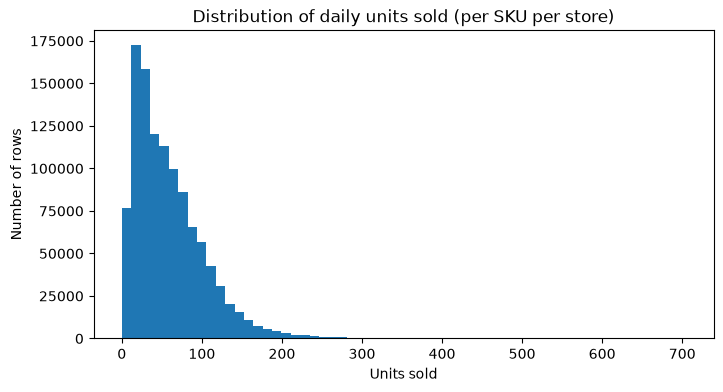

In [24]:
#Histogram of daily units sold: what does the distribution look like?
plt.figure(figsize=(8, 4))
plt.hist(sales["units_sold"], bins=60)
plt.title("Distribution of daily units sold (per SKU per store)")
plt.xlabel("Units sold")
plt.ylabel("Number of rows")
plt.show()

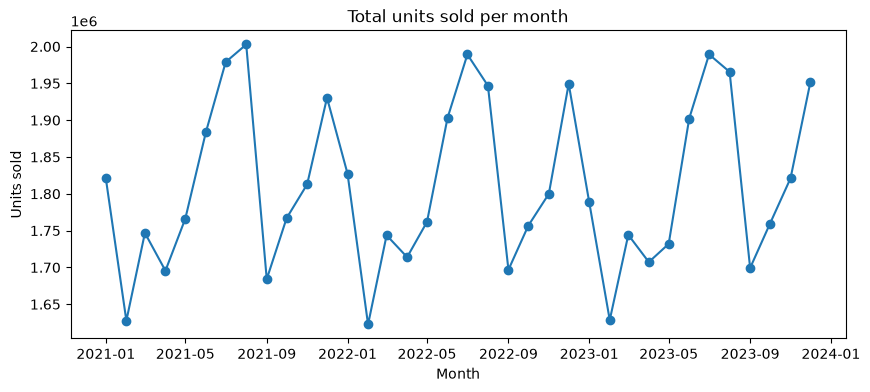

In [25]:
# Total units sold per month: is there a trend or seasonality?
monthly = sales.groupby(sales["date"].dt.to_period("M"))["units_sold"].sum()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Total units sold per month")
plt.xlabel("Month")
plt.ylabel("Units sold")
plt.show()

#### Coefficient of variation (CV) by region
**CV = standard deviation / mean.** It tells us how volatile demand is relative to its size, so it can compare small and big products fairly.

Products sell very different volumes, so I did not calculate one CV over all rows. Instead I calculated the CV of each product in each store over the 3 years, then took the average per country, channel and category.

In [26]:
# Mean and standard deviation of units sold for every store + SKU combination
series = sales.groupby(["country", "channel", "category", "store_id", "sku_id"])["units_sold"].agg(["mean", "std"]).reset_index()

# CV = std / mean
series["cv"] = series["std"] / series["mean"]
print("Number of store-SKU series:", len(series))
series["cv"].describe()

Number of store-SKU series: 1005


count    1005.000000
mean        0.415479
std         0.067295
min         0.322756
25%         0.351293
50%         0.399139
75%         0.478281
max         0.556199
Name: cv, dtype: float64

In [27]:
# Average CV by country, channel and category
cv_country  = series.groupby("country")["cv"].mean().sort_values(ascending=False)
cv_channel  = series.groupby("channel")["cv"].mean().sort_values(ascending=False)
cv_category = series.groupby("category")["cv"].mean().sort_values(ascending=False)

print(cv_country.round(3), "\n")
print(cv_channel.round(3), "\n")
print(cv_category.round(3))

country
Netherlands    0.424
Poland         0.418
France         0.417
Germany        0.416
Italy          0.415
Spain          0.414
Austria        0.412
Name: cv, dtype: float64 

channel
Convenience    0.424
E-commerce     0.415
Hypermarket    0.415
Supermarket    0.415
Name: cv, dtype: float64 

category
Beverages        0.455
Snacks           0.435
Personal Care    0.395
Home Care        0.386
Dairy            0.384
Name: cv, dtype: float64


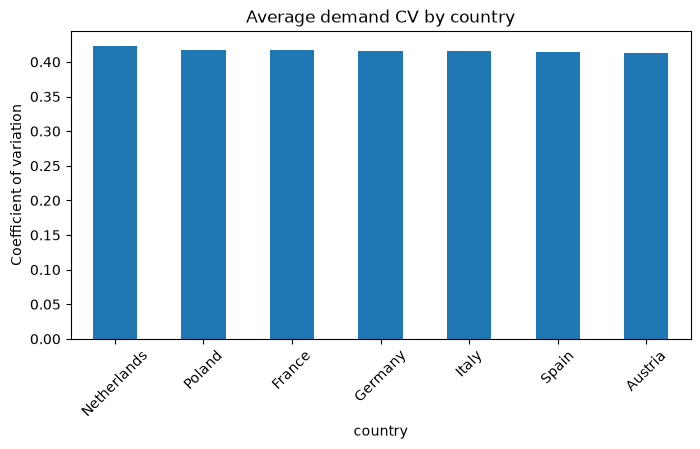

In [28]:
# Bar chart of CV by country (the axis starts at 0 so the size of the differences is honest)
plt.figure(figsize=(8, 4))
cv_country.plot(kind="bar")
plt.title("Average demand CV by country")
plt.ylabel("Coefficient of variation")
plt.xticks(rotation=45)
plt.show()

### 2. Geospatial and logistics analysis
First I made one summary row per store.

In [29]:
# One row per store with totals and averages
store_summary = sales.groupby(["store_id", "city", "country", "channel", "latitude", "longitude"]).agg(
    total_units=("units_sold", "sum"),
    total_net_sales=("net_sales", "sum"),
    avg_lead_time=("lead_time_days", "mean"),
    lead_time_std=("lead_time_days", "std"),
    stockout_rate=("stock_out_flag", "mean"),
).reset_index()

store_summary.sort_values("total_net_sales", ascending=False).round(3)

,store_id,city,country,channel,latitude,longitude,total_units,total_net_sales,avg_lead_time,lead_time_std,stockout_rate
3,STORE0004,Berlin,Germany,Hypermarket,52.501,13.421,6057129,46585753.18,6.505,2.014,0.030
7,STORE0008,Vienna,Austria,Hypermarket,48.203,16.359,5742174,43020025.97,6.494,2.008,0.031
5,STORE0006,Paris,France,Hypermarket,48.876,2.360,6014974,42601612.57,6.500,2.016,0.031
4,STORE0005,Warsaw,Poland,Hypermarket,52.253,20.996,5860180,42385262.52,6.506,2.016,0.030
10,STORE0011,Rome,Italy,Hypermarket,41.908,12.513,5985522,42205660.63,6.497,2.014,0.030
0,STORE0001,Berlin,Germany,Hypermarket,52.526,13.391,5681442,41939805.83,6.506,2.009,0.030
11,STORE0012,Madrid,Spain,E-commerce,40.417,-3.675,5243338,38965417.77,6.512,2.019,0.031
8,STORE0009,Barcelona,Spain,E-commerce,41.367,2.157,5297695,37766116.12,6.497,2.017,0.030
9,STORE0010,Milan,Italy,E-commerce,45.463,9.197,5106947,36002989.23,6.495,2.008,0.030
1,STORE0002,Rome,Italy,Supermarket,41.940,12.506,4249838,30231862.00,6.499,2.012,0.031


With only 13 stores, a smooth heat map would not be meaningful, so I used a bubble map: each bubble is a store, positioned by its latitude and longitude, and the bubble size is its total net sales.

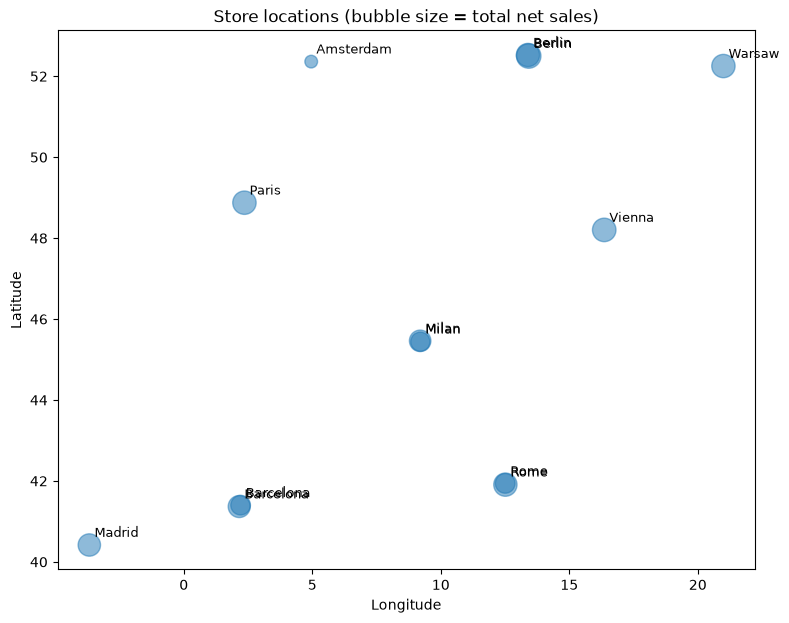

In [30]:
plt.figure(figsize=(9, 7))
plt.scatter(store_summary["longitude"], store_summary["latitude"],
            s=store_summary["total_net_sales"] / 150000, alpha=0.5)

# Write the city name next to each bubble
for i, row in store_summary.iterrows():
    plt.text(row["longitude"] + 0.2, row["latitude"] + 0.2, row["city"], fontsize=9)

plt.title("Store locations (bubble size = total net sales)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

#### Lead time and stockouts
**Logistics desert idea:** a store with high demand and unstable lead times is at risk. I plotted total units against lead-time variability (standard deviation) for each store.

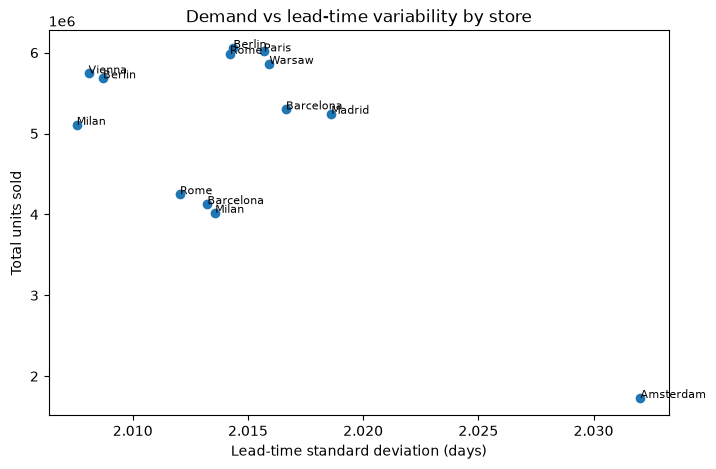

In [31]:
plt.figure(figsize=(8, 5))
plt.scatter(store_summary["lead_time_std"], store_summary["total_units"])
for i, row in store_summary.iterrows():
    plt.text(row["lead_time_std"], row["total_units"], row["city"], fontsize=8)

plt.title("Demand vs lead-time variability by store")
plt.xlabel("Lead-time standard deviation (days)")
plt.ylabel("Total units sold")
plt.show()

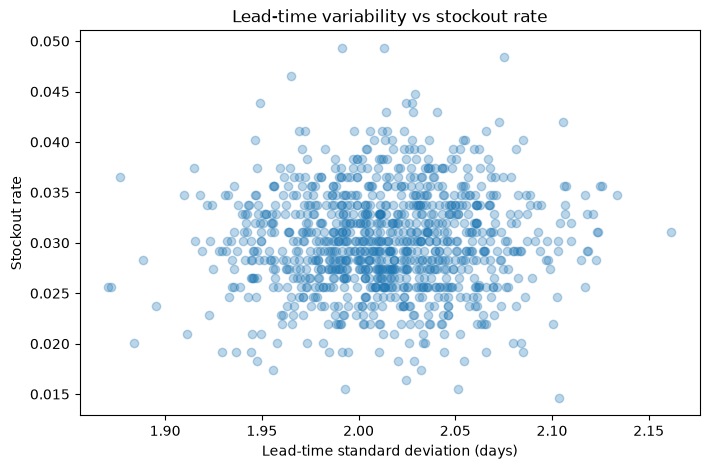

               lead_time_std  stockout_rate
lead_time_std          1.000          0.053
stockout_rate          0.053          1.000


In [32]:
# Scatter plot: lead-time variability vs stockout rate, one point per store + SKU
store_sku = sales.groupby(["store_id", "sku_id"]).agg(
    lead_time_std=("lead_time_days", "std"),
    stockout_rate=("stock_out_flag", "mean"),
).reset_index()

plt.figure(figsize=(8, 5))
plt.scatter(store_sku["lead_time_std"], store_sku["stockout_rate"], alpha=0.3)
plt.title("Lead-time variability vs stockout rate")
plt.xlabel("Lead-time standard deviation (days)")
plt.ylabel("Stockout rate")
plt.show()

# How strong is the relationship? (correlation is between -1 and 1; near 0 means no relationship)
print(store_sku[["lead_time_std", "stockout_rate"]].corr().round(3))

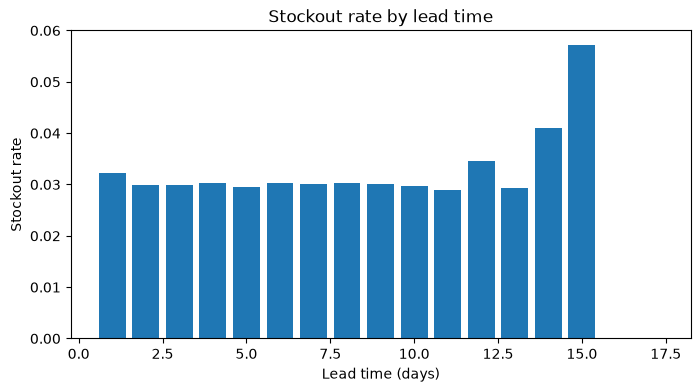

In [33]:
# A more direct look: the stockout rate for each lead time (in days) at the row level
stockout_by_lead = sales.groupby("lead_time_days")["stock_out_flag"].mean()

plt.figure(figsize=(8, 4))
plt.bar(stockout_by_lead.index, stockout_by_lead.values)
plt.title("Stockout rate by lead time")
plt.xlabel("Lead time (days)")
plt.ylabel("Stockout rate")
plt.show()

### 3. ABC analysis (by revenue)
I ranked the SKUs by total net sales and worked out each one's cumulative share of revenue:
- **A** = the SKUs that make up the first 80% of revenue
- **B** = the next 15%
- **C** = the last 5%

In [34]:
# Total net sales per SKU, highest first
sku_revenue = sales.groupby("sku_id")["net_sales"].sum().sort_values(ascending=False).reset_index()

# Share of total revenue and the running (cumulative) share
sku_revenue["revenue_share"] = sku_revenue["net_sales"] / sku_revenue["net_sales"].sum()
sku_revenue["cum_share"] = sku_revenue["revenue_share"].cumsum()

# Assign the class using the cumulative share (the 1.01 is just to catch rounding at 100%)
sku_revenue["abc_class"] = pd.cut(sku_revenue["cum_share"], bins=[0, 0.80, 0.95, 1.01], labels=["A", "B", "C"])

sku_revenue.head()

,sku_id,net_sales,revenue_share,cum_share,abc_class
0,SKU0018,17032424.64,0.036013,0.036013,A
1,SKU0027,16000295.02,0.033831,0.069845,A
2,SKU0026,13025419.73,0.027541,0.097386,A
3,SKU0099,12968809.43,0.027421,0.124807,A
4,SKU0092,12496995.90,0.026424,0.151231,A


In [35]:
# How many SKUs are in each class and how much revenue do they bring?
sku_revenue.groupby("abc_class", observed=True).agg(
    n_skus=("sku_id", "count"),
    revenue_share=("revenue_share", "sum"),
).round(3)

,n_skus,revenue_share
abc_class,,
A,49,0.794
B,29,0.156
C,24,0.050


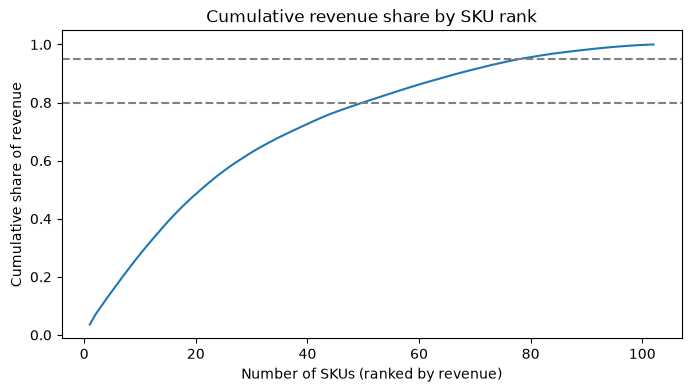

In [36]:
# Pareto-style chart: cumulative revenue share as we add SKUs
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(sku_revenue) + 1), sku_revenue["cum_share"])
plt.axhline(0.80, linestyle="--", color="gray")
plt.axhline(0.95, linestyle="--", color="gray")
plt.title("Cumulative revenue share by SKU rank")
plt.xlabel("Number of SKUs (ranked by revenue)")
plt.ylabel("Cumulative share of revenue")
plt.show()

### 4. XYZ analysis (by demand variability)
For each SKU I added up the units sold across all stores for every day, then calculated the CV of that daily total.

In [37]:
# Daily total units for each SKU (all stores together)
daily_sku = sales.groupby(["sku_id", "date"])["units_sold"].sum().reset_index()

# Mean, std and CV per SKU
sku_cv = daily_sku.groupby("sku_id")["units_sold"].agg(["mean", "std"])
sku_cv["cv"] = sku_cv["std"] / sku_cv["mean"]

print(sku_cv["cv"].describe().round(3))

count    102.000
mean       0.247
std        0.100
min        0.125
25%        0.144
50%        0.235
75%        0.340
max        0.419
Name: cv, dtype: float64


In [38]:
# Common textbook limits are X: CV up to 0.5, Y: 0.5 to 1.0, Z: above 1.0. How many SKUs are above 0.5?
print("SKUs with CV above 0.5:", (sku_cv["cv"] > 0.5).sum())

SKUs with CV above 0.5: 0


**Observation:** no SKU has a CV above 0.5, so the textbook limits would label every SKU as X and tell us nothing. Because demand is quite stable across the board in this dataset, I used a relative split instead: the third of SKUs with the lowest CV are X, the middle third Y and the highest third Z. 

In [39]:
# Split the SKUs into three equal-sized groups by CV
sku_cv["xyz_class"] = pd.qcut(sku_cv["cv"], 3, labels=["X", "Y", "Z"])

# What CV range does each class cover?
sku_cv.groupby("xyz_class", observed=True)["cv"].agg(["count", "min", "max"]).round(3)

,count,min,max
xyz_class,,,
X,34,0.125,0.151
Y,34,0.151,0.334
Z,34,0.335,0.419


### 5. Combined ABC-XYZ matrix

In [40]:
# Bring the SKU names and categories in, then combine the two classifications
sku_info = sales[["sku_id", "sku_name", "category"]].drop_duplicates()

segments = sku_revenue.merge(sku_cv[["cv", "xyz_class"]], on="sku_id").merge(sku_info, on="sku_id")
segments["segment"] = segments["abc_class"].astype(str) + segments["xyz_class"].astype(str)

# Matrix: number of SKUs in each ABC / XYZ combination
pd.crosstab(segments["abc_class"], segments["xyz_class"])

xyz_class,X,Y,Z
abc_class,,,
A,17,15,17
B,9,9,11
C,8,10,6


In [41]:
# Which categories do the A-class SKUs belong to?
pd.crosstab(segments["category"], segments["abc_class"])

abc_class,A,B,C
category,,,
Beverages,10,8,6
Dairy,8,4,6
Home Care,10,4,4
Personal Care,8,7,3
Snacks,13,6,5


### 6. Regional comparison
I repeated the ABC analysis inside each country to see if a SKU's class changes from country to country.

In [42]:
# Revenue of each SKU in each country
country_rev = sales.groupby(["country", "sku_id"])["net_sales"].sum().reset_index()

# Rank within each country and work out the cumulative share inside that country
country_rev = country_rev.sort_values(["country", "net_sales"], ascending=[True, False])
country_total = country_rev.groupby("country")["net_sales"].transform("sum")
country_rev["share"] = country_rev["net_sales"] / country_total
country_rev["cum_share"] = country_rev.groupby("country")["share"].cumsum()

country_rev["abc_class"] = pd.cut(country_rev["cum_share"], bins=[0, 0.80, 0.95, 1.01], labels=["A", "B", "C"])

# How many SKUs of each class does each country have?
pd.crosstab(country_rev["country"], country_rev["abc_class"])

abc_class,A,B,C
country,,,
Austria,38,23,19
France,37,23,20
Germany,44,28,26
Italy,49,29,24
Netherlands,21,13,11
Poland,39,23,18
Spain,46,29,25


In [43]:
# One row per SKU, one column per country, showing its class there
abc_by_country = country_rev.pivot(index="sku_id", columns="country", values="abc_class")

# SKUs that are an A-product in at least one country AND a C-product in another
is_A_somewhere = (abc_by_country == "A").any(axis=1)
is_C_somewhere = (abc_by_country == "C").any(axis=1)
switchers = abc_by_country[is_A_somewhere & is_C_somewhere]

print(len(switchers), "SKUs are A in one country and C in another")
switchers.head(10)

6 SKUs are A in one country and C in another


country,Austria,France,Germany,Italy,Netherlands,Poland,Spain
sku_id,,,,,,,
SKU0014,B,NaN,B,A,B,B,C
SKU0043,B,NaN,C,A,NaN,B,B
SKU0049,A,NaN,A,C,A,A,A
SKU0072,B,B,A,C,NaN,B,A
SKU0080,A,NaN,B,C,A,A,A
SKU0088,B,B,C,A,NaN,B,B


### 7. Save the SKU segments for the next steps

In [44]:
segments.to_csv("data/processed/sku_segments.csv", index=False)
print("Saved", len(segments), "SKUs")
segments.head()

Saved 102 SKUs


,sku_id,net_sales,revenue_share,cum_share,abc_class,cv,xyz_class,sku_name,category,segment
0,SKU0018,17032424.64,0.036013,0.036013,A,0.236804,Y,BrandF Water,Beverages,AY
1,SKU0027,16000295.02,0.033831,0.069845,A,0.333479,Y,BrandC Chips,Snacks,AY
2,SKU0026,13025419.73,0.027541,0.097386,A,0.175707,Y,BrandB Chips,Snacks,AY
3,SKU0099,12968809.43,0.027421,0.124807,A,0.341418,Z,BrandC Toothpaste,Personal Care,AZ
4,SKU0092,12496995.90,0.026424,0.151231,A,0.138370,X,BrandB Soap,Personal Care,AX


# Step 3: Statistical Rigor and Hypothesis Testing

What I want to find out:
1. How are price, promotion and sales volume related? (correlation matrix)
2. How sensitive is demand to price for the A-class products? (price elasticity)
3. Do promotions really increase sales, or is it just chance? (hypothesis test)
4. How should I split the data into training and test sets for a time series? (time-based split)

In [45]:
# Extra libraries needed for Step 3 (pandas and matplotlib were imported in Step 1)
import numpy as np
import seaborn as sns
from scipy import stats

# The price a customer actually pays = list price minus the discount
sales["net_price"] = sales["list_price"] * (1 - sales["promo_discount"])
print(sales.shape)
sales.info()

(1100000, 34)
<class 'pandas.DataFrame'>
RangeIndex: 1100000 entries, 0 to 1099999
Data columns (total 34 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   date            1100000 non-null  datetime64[us]
 1   year            1100000 non-null  int64         
 2   month           1100000 non-null  int64         
 3   day             1100000 non-null  int64         
 4   weekofyear      1100000 non-null  int64         
 5   weekday         1100000 non-null  int64         
 6   is_weekend      1100000 non-null  int64         
 7   is_holiday      1100000 non-null  int64         
 8   temperature     1100000 non-null  float64       
 9   rain_mm         1100000 non-null  float64       
 10  store_id        1100000 non-null  str           
 11  country         1100000 non-null  str           
 12  city            1100000 non-null  str           
 13  channel         1100000 non-null  str           
 14  latitude       

### 1. How do price and promotions work in this data?
Before any statistics, we need to do two quick checks.

In [46]:
# 1) Does the list price of a SKU ever change?
print("Most different list prices for one SKU:", sales.groupby("sku_id")["list_price"].nunique().max())

# 2) How many SKUs are ever on promotion?
promo_days_per_sku = sales.groupby("sku_id")["on_promo"].sum()
print("SKUs with promo days:", (promo_days_per_sku > 0).sum())
print("SKUs never on promo :", (promo_days_per_sku == 0).sum())

# 3) Which discount levels exist?
print("Discount levels:", sorted(sales["promo_discount"].unique()))

Most different list prices for one SKU: 1
SKUs with promo days: 41
SKUs never on promo : 61
Discount levels: [np.float64(0.0), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3)]


**What this means:**
- The list price of every SKU is constant, so the only way a product's price changes over time is through a **promotional discount**.
- Many SKUs are **never promoted**, so they have no price changes at all. I cannot measure price elasticity for them.

### 2. Correlation matrix
Correlation measures how two variables move together, from -1 (opposite directions) through 0 (no relationship) to +1 (same direction).

I added one extra column, `units_vs_sku_avg`, which is units sold divided by that SKU's own average. It removes the fact that some products simply sell more than others, so it shows the effect of price and promotion (within) each product.

In [47]:
# Units relative to each SKU's own average (1.0 = a normal day for that SKU)
sales["units_vs_sku_avg"] = sales["units_sold"] / sales.groupby("sku_id")["units_sold"].transform("mean")

corr_cols = ["units_sold", "units_vs_sku_avg", "list_price", "promo_discount", "on_promo"]
corr = sales[corr_cols].corr()
corr.round(3)

,units_sold,units_vs_sku_avg,list_price,promo_discount,on_promo
units_sold,1.000,0.618,-0.083,0.293,0.296
units_vs_sku_avg,0.618,1.000,0.000,0.384,0.383
list_price,-0.083,0.000,1.000,-0.043,-0.048
promo_discount,0.293,0.384,-0.043,1.000,0.925
on_promo,0.296,0.383,-0.048,0.925,1.000


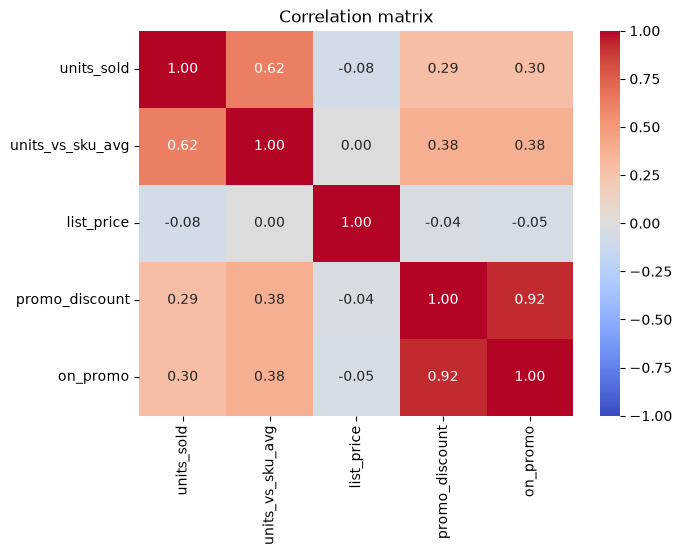

In [48]:
# Heat map of the correlations
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

### 3. Price elasticity for the A-class products
**Price elasticity** = the % change in units sold when the price changes by 1%.

I use a **log-log regression**: I take the logarithm of units and of price and fit a straight line. The slope of that line is the elasticity. For example, a slope of -2 means a 1% lower price gives about 2% more units.

I did this separately for each A-class SKU, using the net price (list price after discount). I left out zero-sales days because the log of 0 does not exist.

In [49]:
# A-class SKUs from Step 2
a_skus = segments.loc[segments["abc_class"] == "A", "sku_id"].tolist()

# Elasticity needs a price that changes, so keep only the A-SKUs that are ever on promotion
a_skus_promoted = [sku for sku in a_skus if promo_days_per_sku[sku] > 0]

print("A-class SKUs                               :", len(a_skus))
print("A-class SKUs of which have price changes   :", len(a_skus_promoted))
print("A-class SKUsnever promoted (no elasticity) :", len(a_skus) - len(a_skus_promoted))

A-class SKUs                               : 49
A-class SKUs of which have price changes   : 20
A-class SKUsnever promoted (no elasticity) : 29


In [50]:
def get_elasticity(data):
    # Drop zero-sales days (log of 0 does not exist)
    data = data[data["units_sold"] > 0]
    # Fit: log(units) = intercept + slope * log(price). The slope is the elasticity.
    result = stats.linregress(np.log(data["net_price"]), np.log(data["units_sold"]))
    return result.slope, result.pvalue


# Calculate the elasticity of every A-SKU that has promotions, using all its days
results = []
for sku in a_skus_promoted:
    sku_data = sales[sales["sku_id"] == sku]
    slope, p_value = get_elasticity(sku_data)
    results.append({"sku_id": sku, "elasticity": slope, "p_value": p_value})

elasticity_all = pd.DataFrame(results)
print("Elasticity of A-SKUs (all days):")
print(elasticity_all["elasticity"].describe().round(2))
print("SKUs with a significant result (p < 0.05):", (elasticity_all["p_value"] < 0.05).sum(), "of", len(elasticity_all))

Elasticity of A-SKUs (all days):
count    20.00
mean     -2.53
std       0.06
min      -2.69
25%      -2.56
50%      -2.54
75%      -2.49
max      -2.42
Name: elasticity, dtype: float64
SKUs with a significant result (p < 0.05): 20 of 20


The result above mixes two things: whether a promotion is running at all, and how deep the discount is. To separate them, I repeated the calculation using **only promotion days**, so the price only changed between the 10%, 15%, 20% and 30% discount levels.

In [51]:
# Same calculation, but only on days when a promotion was running
results = []
for sku in a_skus_promoted:
    sku_data = sales[(sales["sku_id"] == sku) & (sales["on_promo"] == 1)]
    slope, p_value = get_elasticity(sku_data)
    results.append({"sku_id": sku, "elasticity": slope, "p_value": p_value})

elasticity_promo = pd.DataFrame(results)
print("Elasticity of A-SKUs (promotion days only):")
print(elasticity_promo["elasticity"].describe().round(2))

Elasticity of A-SKUs (promotion days only):
count    20.00
mean     -0.86
std       0.14
min      -1.07
25%      -0.96
50%      -0.90
75%      -0.74
max      -0.54
Name: elasticity, dtype: float64


In [52]:
# Compare the two results side by side
comparison = pd.DataFrame({
    "all_days": elasticity_all["elasticity"].describe(),
    "promo_days_only": elasticity_promo["elasticity"].describe(),
}).round(2)
comparison

,all_days,promo_days_only
count,20.00,20.00
mean,-2.53,-0.86
std,0.06,0.14
min,-2.69,-1.07
25%,-2.56,-0.96
50%,-2.54,-0.90
75%,-2.49,-0.74
max,-2.42,-0.54


**How to read this:** an elasticity below -1 means demand is *elastic* (a price cut brings a more-than-proportional rise in units, so revenue goes up). Between -1 and 0 it is *inelastic*. The two numbers answer different questions. The first says how much demand rises when a product goes on promotion. The second says how much *extra* demand a deeper discount adds once a promotion is already running.

### 4. Hypothesis test: do promotions increase sales?
* **H0 (null hypothesis):** average units sold on promotion days = average units sold on non-promotion days.
* **H1 (alternative):** the averages are different.
* **Significance level:** alpha = 0.05. If the p-value is below 0.05, I reject H0.

I run two tests:
* **Welch's t-test** compares the two averages (it does not assume equal variances).
* **Mann-Whitney U test** compares the two distributions without assuming a normal shape. Daily sales are right-skewed (Step 2), so this one is a good fit.

In [53]:
# Average sales on promotion days vs non-promotion days
group_stats = sales.groupby("on_promo")["units_sold"].agg(["mean", "median", "std", "count"]).round(1)
group_stats.index = ["No promotion", "Promotion"]
group_stats

,mean,median,std,count
No promotion,55.3,46.0,39.2,1011743
Promotion,104.3,89.0,73.7,88257


In [54]:
promo_units = sales.loc[sales["on_promo"] == 1, "units_sold"]
no_promo_units = sales.loc[sales["on_promo"] == 0, "units_sold"]

# Lift = how much higher is the promotion average, in %
lift = (promo_units.mean() / no_promo_units.mean() - 1) * 100
print(f"Promotion lift: {lift:.1f}%")

# Run both tests
t_stat, t_p = stats.ttest_ind(promo_units, no_promo_units, equal_var=False)
u_stat, u_p = stats.mannwhitneyu(promo_units, no_promo_units)

alpha = 0.05
# A p-value shown as 0.0 means it is too small for the computer to display: report it as p < 0.001
print("T-test p-value       :", t_p)
print("Mann-Whitney p-value :", u_p)

if t_p < alpha and u_p < alpha:
    print("Both p-values are below 0.05, so I reject H0: promotions change sales.")
else:
    print("I cannot reject H0.")

Promotion lift: 88.7%
T-test p-value       : 0.0
Mann-Whitney p-value : 0.0
Both p-values are below 0.05, so I reject H0: promotions change sales.


#### Robustness check
A fair worry: maybe the promoted products are simply bigger sellers. To check, I compare promotion days and non-promotion days **inside the same product and store**. Only SKUs that are ever promoted are included. If promotions really work, almost every store-SKU should sell more on its promo days.

In [55]:
# Keep only SKUs that are ever promoted
promoted_skus = promo_days_per_sku[promo_days_per_sku > 0].index
promoted = sales[sales["sku_id"].isin(promoted_skus)]

# Average units on promo days and non-promo days for each store + SKU
series_avg = promoted.groupby(["store_id", "sku_id", "on_promo"])["units_sold"].mean().unstack()
series_avg = series_avg.dropna()                      # keep series that have both kinds of days
series_avg.columns = ["non_promo_avg", "promo_avg"]   # the columns are in the order 0, 1
series_avg["lift"] = series_avg["promo_avg"] / series_avg["non_promo_avg"]

print("Store-SKU series compared:", len(series_avg))
print("Series that sell more on promo days:", (series_avg["lift"] > 1).sum())
print("Average lift (promo avg / normal avg):", round(series_avg["lift"].mean(), 2))
print("Lowest / highest lift:", round(series_avg["lift"].min(), 2), "/", round(series_avg["lift"].max(), 2))

# Paired t-test: the same series measured twice (on promo days and on normal days)
paired_t, paired_p = stats.ttest_rel(series_avg["promo_avg"], series_avg["non_promo_avg"])
print("Paired t-test p-value:", paired_p)

Store-SKU series compared: 403
Series that sell more on promo days: 403
Average lift (promo avg / normal avg): 1.87
Lowest / highest lift: 1.7 / 2.03
Paired t-test p-value: 6.82215376492626e-129


promo_discount
0.00     55.3
0.10     94.3
0.15    100.3
0.20    106.7
0.30    116.2
Name: units_sold, dtype: float64


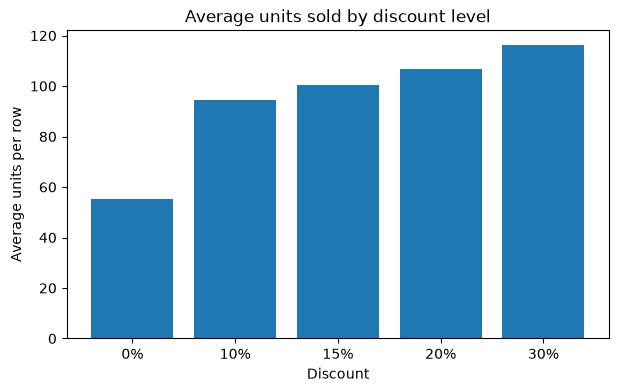

In [56]:
# Does a deeper discount sell more? Average units by discount level
by_discount = sales.groupby("promo_discount")["units_sold"].mean().round(1)
print(by_discount)

plt.figure(figsize=(7, 4))
plt.bar(["0%", "10%", "15%", "20%", "30%"], by_discount.values)
plt.title("Average units sold by discount level")
plt.xlabel("Discount")
plt.ylabel("Average units per row")
plt.show()

**Important to note:** these tests assume the observations are independent, but daily sales of one product in one store are linked over time. That makes the p-values look (better than they really are). With more than a million rows the p-value will be tiny almost no matter what, so the **size of the lift** (about +89%) is more informative than the p-value itself.

### 5. Time-series split (train and test)
**Warning from the guide:** never shuffle a time series randomly. Random shuffling would put future days in the training set and past days in the test set, which would leak information and make the model look better than it really is.

Instead I used a **time-based split**: the last 6 months (July to December 2023) are the hold-out test set, and everything before is the training set.

In [57]:
SPLIT_DATE = pd.Timestamp("2023-07-01")

train = sales[sales["date"] < SPLIT_DATE]
test = sales[sales["date"] >= SPLIT_DATE]

print("Train:", len(train), "rows |", train["date"].min().date(), "to", train["date"].max().date())
print("Test :", len(test), "rows |", test["date"].min().date(), "to", test["date"].max().date())
print(f"Test share of all rows: {len(test) / len(sales):.1%}")

# The most important check: every training date comes before every test date
print("Training ends before test starts:", train["date"].max() < test["date"].min())

Train: 915264 rows | 2021-01-01 to 2023-06-30
Test : 184736 rows | 2023-07-01 to 2023-12-31
Test share of all rows: 16.8%
Training ends before test starts: True


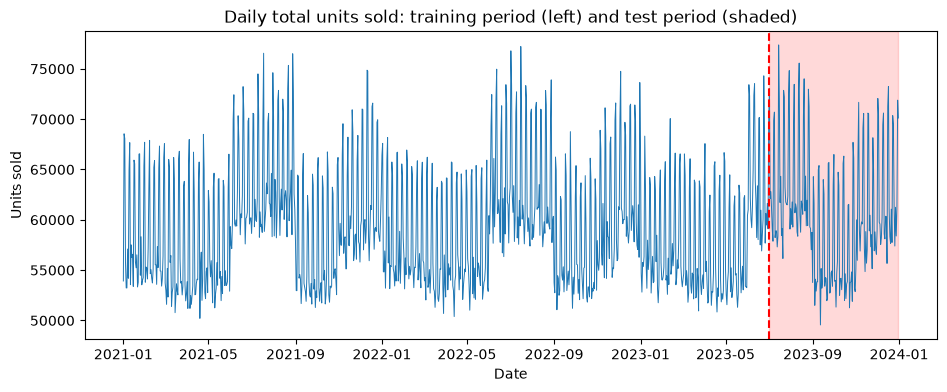

In [58]:
# Plot total daily units and mark the split
daily_total = sales.groupby("date")["units_sold"].sum()

plt.figure(figsize=(11, 4))
plt.plot(daily_total.index, daily_total.values, linewidth=0.7)
plt.axvline(SPLIT_DATE, color="red", linestyle="--")
plt.axvspan(SPLIT_DATE, daily_total.index.max(), alpha=0.15, color="red")
plt.title("Daily total units sold: training period (left) and test period (shaded)")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.show()

In [59]:
# Are the train and test sets similar? (promotion share and average sales)
check = pd.DataFrame({
    "promo_share": [train["on_promo"].mean(), test["on_promo"].mean()],
    "avg_units": [train["units_sold"].mean(), test["units_sold"].mean()],
}, index=["Train", "Test"]).round(3)
check

,promo_share,avg_units
Train,0.08,58.923
Test,0.08,60.552


The test period contains the summer peak (July and August) and the December peak. The training data includes those same seasons for 2021 and 2022.